# Clio-Infra at historical borders — a first look

The same indicators as `notebooks/clio`, deposited on DataverseNL with a
different geography: **one row per historical border period** rather than one
per modern country. One dataset so far — Labourers Real Wage.

**How it got here.** DataverseNL sits behind a bot check that refuses
automated clients outright (headless Brave was denied on sight), so there is no
scripted download. A dataset is downloaded by hand in a browser, then filed with
`utils.accept.accept(folder, doi=..., version=...)`, which copies it to
`data/raw/<doi>/` and records the DOI, the deposit version and the download date
in `data/manifest.json`. The source folder is copied, not moved.

**Output**, under `notebooks/clio_historical/data/` (gitignored):

| path | what |
| --- | --- |
| `raw/<doi>/*-historical.xlsx` | the workbook |
| `raw/<doi>/*.docx` | the working paper — the only statement of units and data quality |
| `raw/<doi>/MANIFEST.TXT` | Dataverse's own file list |
| `manifest.json` | DOI, version, release and download dates, sha256 per file |

In [1]:
import sys
sys.path.append("../")
sys.path.append("../../")

import json
from collections import Counter, defaultdict
from pathlib import Path

import pandas
from matplotlib import pyplot

from lib import config
from utils import accept, documentation, workbook, xlsx

pyplot.style.use(config.glyfish_style)
pandas.set_option("display.width", 160)

manifest = json.loads((accept.DATA_DIR / accept.MANIFEST).read_text())
pandas.DataFrame(manifest.values())[["doi", "version", "released", "downloaded", "workbook"]]

,doi,version,released,downloaded,workbook
0,10.34894/UFVNXT,1.1,2026-01-08,2026-09-19,Labourers_wage-historical.xlsx


## The workbook

One sheet, wide by year. Row 1 is the indicator, row 2 the **unit** — which the
main site's files do not state anywhere — and row 3 the header.

In [2]:
entry = manifest["10.34894/UFVNXT"]
folder = accept.DATA_DIR / accept.RAW / accept.doi_dir(entry["doi"])
book = workbook.read(folder / entry["workbook"])
records = workbook.long_records(book)

print(f"{book['title']}\n  unit: {book['unit']}\n")
with_values = [p for p in book["polities"] if p["values"]]
print(f"{len(book['polities']):,} polity-periods, {len(with_values)} with values, "
      f"{len(records):,} values ({sum(r['in_border_period'] for r in records):,} inside their border period)")

Labourers Real Wage
  unit: Number of daily subsistence baskets that a daily wage buys

1,412 polity-periods, 254 with values, 7,542 values (4,649 inside their border period)


## Two border schemes in one sheet

They mean different things, and reading them alike double-counts:

- **`geacron/…`** — a historical border period. Its values lie inside its own
  start and end years. It never carries a modern country code.
- **`cshapes/…`** — a post-1946 state. Its row holds the **whole** modern series,
  reaching back before 1946.

So a pre-1946 year for a continuing state appears twice. The United Kingdom:

In [3]:
uk = [p for p in book["polities"] if p["name"] == "United Kingdom" and p["values"]]
pandas.DataFrame([{"code": p["code"], "borders": f"{p['border_start']}–{p['border_end']}",
                   "values": len(p["values"]),
                   "years": f"{min(p['values'])}–{max(p['values'])}"} for p in uk])

,code,borders,values,years
0,geacron/1101,1820–1839,20,1820–1839
1,geacron/1102,1840–1939,100,1840–1939
2,geacron/1103,1940–1945,6,1940–1945
3,cshapes/1434,1946–2012,175,1820–2006


The CShapes row runs 1820–2006 — it is the main site's United Kingdom series,
value for value. The GeaCron rows cut the same years into the border periods
in force at the time.

## Against the main site

Every value here, checked against `notebooks/clio`'s copy of the same indicator.

In [4]:
main_file = Path("../clio/data/raw/LabourersRealWage_Compact.xlsx")
main = defaultdict(dict); main_rows = xlsx.records(main_file, "Data Long Format")
by_value = defaultdict(set)
for r in main_rows:
    y, v = int(float(r["year"])), float(r["value"])
    main[r["country.name"]][y] = v
    by_value[(y, round(v, 6))].add(r["country.name"])

kind, renamed, revised, new = Counter(), defaultdict(Counter), [], Counter()
for r in records:
    known = main.get(r["name"], {}).get(r["year"])
    if known is not None:
        if abs(known - r["value"]) < 1e-6: kind["identical"] += 1
        else: kind["revised"] += 1; revised.append((r["name"], r["year"], known, r["value"]))
        continue
    hit = by_value.get((r["year"], round(r["value"], 6)))
    if hit: kind["renamed"] += 1; renamed[r["name"]][next(iter(hit))] += 1
    else: kind["new"] += 1; new[r["name"]] += 1

pandas.Series(kind, name="values").to_frame()

,values
identical,6993
revised,64
renamed,294
new,191


In [5]:
print("renamed — the main site files historical states under today's country:")
for name, to in sorted(renamed.items(), key=lambda kv: -sum(kv[1].values())):
    print(f"  {name:26s} -> {', '.join(to)}")
print("\nnew — not on the main site at all:")
for name, k in new.most_common(): print(f"  {k:3d}  {name}")
print(f"\nrevised — {len(revised)} values, all {', '.join(sorted({n for n, *_ in revised}))}:")
for name, y, old, now in revised[:4]:
    print(f"  {name} {y}: main site {old:.1f}, DataverseNL {now:.1f}  ({now/old - 1:+.0%})")

renamed — the main site files historical states under today's country:
  Gambia                     -> The Gambia
  German Confederation       -> Germany
  Ottoman                    -> Turkey
  West Germany               -> Germany
  Germany Federal Republic   -> Germany
  Czechoslovakia             -> Czech Republic
  Ceylon                     -> Sri Lanka
  Canada                     -> United States

new — not on the main site at all:
   55  Falklands
   51  Tanzania
   48  Hong Kong
   11  Vietnam
    8  Yugoslavia
    6  Israel
    6  Ethiopia
    5  Yemen Arab Republic
    1  German Confederation

revised — 64 values, all Canada, Israel, Netherlands:
  Canada 1925: main site 38.4, DataverseNL 68.5  (+78%)
  Canada 1926: main site 36.9, DataverseNL 70.7  (+91%)
  Canada 1927: main site 42.8, DataverseNL 80.6  (+88%)
  Canada 1930: main site 42.1, DataverseNL 70.9  (+68%)


Four findings, each checked below rather than read off the counts:

1. **The difference is mainly geography.** The main site assigns historical
   states to their modern successor: Ottoman wages are *Turkey*'s, the German
   Confederation's are *Germany*'s, Ceylon's are *Sri Lanka*'s. Here they keep
   their own names and borders -- the Ottoman Empire of 1850 is not modern
   Turkey.
2. **The Netherlands before 1840 includes Belgium** -- the one place the numbers
   differ because the borders do. Every value lies between the main site's
   Netherlands and Belgium, at about two-thirds and one-third.
3. **The historical Canada rows are the United States.** Not a revision: every
   value in them equals the US series to the digit, and none equals Canada's.
   The modern Canada row agrees with the main site exactly. A labelling error in
   the deposit -- and the main site's two uncoded "Canada" values for 1946-47 are
   the same US numbers, so it is there too.
4. **Israel's first row is unexplained** -- four values that look shifted by a
   decade. The rest are new: Falklands, Tanzania and Hong Kong mostly.

In [6]:
# 3. Canada: which country's numbers does each row actually hold?
rows = []
for p in book["polities"]:
    if p["name"] != "Canada" or not p["values"]: continue
    ys = sorted(p["values"])
    rows.append({"code": p["code"], "borders": f"{p['border_start']}-{p['border_end']}",
                 "values": len(ys), "years": f"{ys[0]}-{ys[-1]}",
                 "equal to Canada": sum(abs(main["Canada"].get(y, -1) - p["values"][y]) < 1e-6 for y in ys),
                 "equal to United States": sum(abs(main["United States"].get(y, -1) - p["values"][y]) < 1e-6 for y in ys)})
pandas.DataFrame(rows)

,code,borders,values,years,equal to Canada,equal to United States
0,geacron/236,1880-1939,14,1925-1939,0,14
1,geacron/237,1900-1939,14,1925-1939,0,14
2,geacron/238,1940-1945,6,1940-1945,0,6
3,geacron/239,1940-1945,6,1940-1945,0,6
4,cshapes/1420,1946-2012,2,1946-1947,0,2
5,cshapes/1593,1948-2012,58,1925-2008,58,0


In [7]:
# 2. The Netherlands, 1820-1839: where between the Dutch and Belgian series?
nl = next(p for p in book["polities"] if p["name"] == "Netherlands" and p["border_start"] == 1820)
share = pandas.DataFrame([{"year": y, "here": v, "main site Netherlands": main["Netherlands"][y],
                           "main site Belgium": main["Belgium"][y],
                           "Belgian share": (v - main["Netherlands"][y]) / (main["Belgium"][y] - main["Netherlands"][y])}
                          for y, v in sorted(nl["values"].items())
                          if y in main["Belgium"] and abs(main["Belgium"][y] - main["Netherlands"][y]) > 0.5])
print(f"Belgian share: median {share['Belgian share'].median():.3f}, "
      f"range {share['Belgian share'].min():.3f}-{share['Belgian share'].max():.3f}")
share.head(6).round(3)

Belgian share: median 0.333, range 0.333-0.333


,year,here,main site Netherlands,main site Belgium,Belgian share
0,1820,14.754,13.817,16.627,0.333
1,1821,16.035,14.198,19.709,0.333
2,1822,21.361,21.192,21.699,0.333
3,1824,22.225,20.765,25.146,0.333
4,1825,20.840,19.497,23.526,0.333
5,1826,17.184,15.572,20.408,0.333


Text(0.995, 0.005, 'doi:10.34894/UFVNXT v1.1  cshapes/1594, geacron/388-391, cshapes/1598')

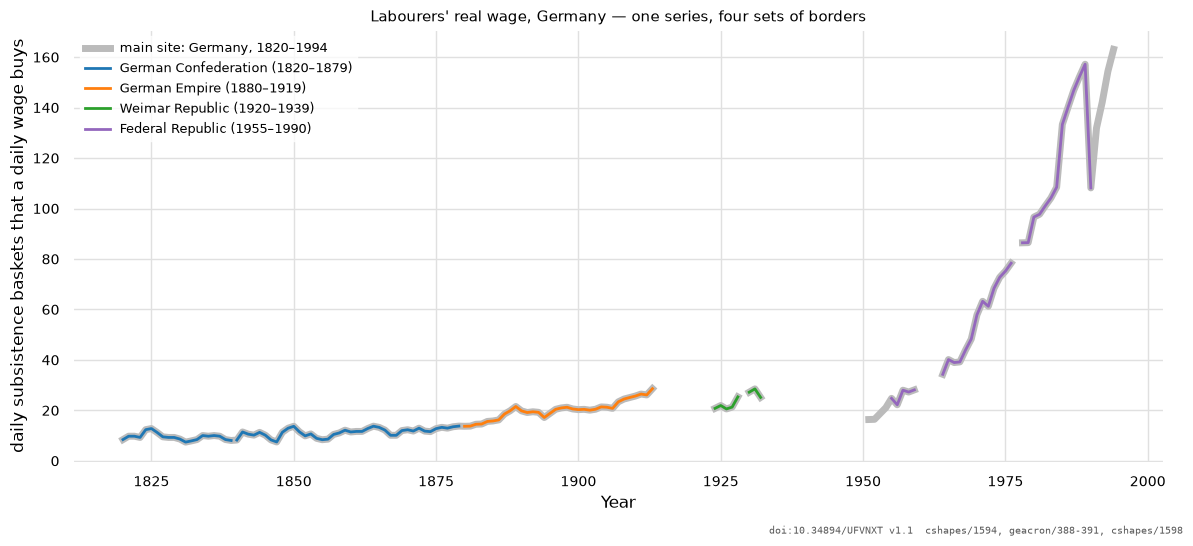

In [8]:
germany = {p["code"]: p for p in book["polities"] if p["values"]}
modern = germany["cshapes/1594"]
periods = [("geacron/388", "German Confederation"), ("geacron/389", "German Confederation"),
           ("geacron/390", "German Empire"), ("geacron/391", "Weimar Republic"),
           ("cshapes/1598", "Federal Republic")]
colour = {"German Confederation": "tab:blue", "German Empire": "tab:orange",
          "Weimar Republic": "tab:green", "Federal Republic": "tab:purple"}

figure, axis = pyplot.subplots(figsize=(12, 5.5))
# a missing year breaks the line rather than being bridged
years = list(range(min(modern["values"]), max(modern["values"]) + 1))
axis.plot(years, [modern["values"].get(y, float("nan")) for y in years], color="#bbbbbb", lw=5,
          label="main site: Germany, 1820–1994", zorder=1)
shown = set()
for code_, label in periods:
    p = germany[code_]
    lo = max(min(p["values"]), p["border_start"]); hi = min(max(p["values"]), p["border_end"])
    ys = list(range(lo, hi + 1))
    axis.plot(ys, [p["values"].get(y, float("nan")) for y in ys], color=colour[label], lw=2, zorder=2,
              label=None if label in shown else f"{label} ({p['border_start']}–{p['border_end'] if label != 'German Confederation' else 1879})")
    shown.add(label)
axis.set_ylabel(book["unit"].lower().replace("number of ", ""))
axis.set_xlabel("Year")
axis.set_title("Labourers' real wage, Germany — one series, four sets of borders", fontsize=11)
axis.legend(loc="upper left", fontsize=9)
figure.tight_layout()
figure.subplots_adjust(bottom=0.14)
figure.text(0.995, 0.005, f"doi:{entry['doi']} v{entry['version']}  cshapes/1594, geacron/388-391, cshapes/1598",
            ha="right", va="bottom", fontsize=7, family="monospace", alpha=0.65)

The colours sit exactly on the grey -- the numbers are the same. What the file
adds is the statement that the 1850 value describes the German Confederation,
not the Germany of 1994. The breaks are real gaps in the record -- 1914-1923,
1933-1950, and shorter ones in 1929, 1960-63 and 1977 -- and neither version
has data for them.

## The working paper

Each deposit carries a `.docx` in a fixed sixteen-section template. Two of its
sections exist nowhere else.

In [9]:
paper = documentation.sections(folder / "Labourers_wage.docx")
for key in ("7. Unit of analysis", "10. Time period", "13. Data quality"):
    print(f"{key}\n  " + paper[key].replace("\n", "\n  ") + "\n")

7. Unit of analysis
  number of subsistence baskets.

10. Time period
  1820-2000.

13. Data quality
  i. Central statistical agencies
  ii. Historical reconstructions
  iii. Estimates
  iv. Conjectures
  Virtually all benchmark data after the 1920s are derived indirectly from Central Statistical Agencies and therefore probably better classify as historical reconstructions. The remaining data are estimates.



The data-quality section grades sources on four tiers -- central statistical
agencies, historical reconstructions, estimates, conjectures -- and says this
series is **estimates before the 1920s and reconstructions after**. Nothing on
the main site says so.

## What this means for storing it

It is almost entirely historical and cannot be scripted, so it is managed by
hand: each series carries the DOI, the **deposit version** and the download
date, and is refreshed only when a dataset of interest is re-downloaded. The
version says what you have; the date only says when you looked.

Two things to settle before building series from it: which border scheme a
stored series follows -- the GeaCron periods, or the CShapes row that duplicates
the main site -- and what to do with rows that are wrong, like pre-1948 Canada.